# 3 · Stochastic volatility and jumps: Heston, Merton, Bates
All three models are priced with one Fourier engine (Lewis 2001) and cross-checked against Monte Carlo.
Model prices are turned into Black-Scholes implied volatilities to show **why** these models exist: they generate the smile and skew seen in markets.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from derivpricer import black_scholes as bs, heston, merton, bates

In [2]:
S0, r, T = 80.0, 0.055, 0.25
hp = heston.HestonParams(v0=0.032, kappa=1.8, theta=0.045, xi=0.35, rho=-0.30)
mp = merton.MertonParams(sigma=0.35, lam=0.75, mu_j=-0.5, delta=0.22)
bp = bates.BatesParams(*vars(hp).values(), lam=0.75, mu_j=-0.5, delta=0.22)
print("Heston Feller condition satisfied:", hp.feller)

Heston Feller condition satisfied: True


## Fourier vs Monte Carlo (ATM, 3 months)

In [3]:
K = S0
rows = []
for name, four, mcres in [
    ("Heston rho=-0.30", heston.price(S0, K, T, r, hp), heston.price_mc(S0, K, T, r, hp, n_steps=100)),
    ("Heston rho=-0.70", heston.price(S0, K, T, r, heston.HestonParams(0.032, 1.8, 0.045, 0.35, -0.70)),
                         heston.price_mc(S0, K, T, r, heston.HestonParams(0.032, 1.8, 0.045, 0.35, -0.70), n_steps=100)),
    ("Merton lam=0.75", merton.price(S0, K, T, r, mp), merton.price_mc(S0, K, T, r, mp)),
    ("Merton lam=0.25", merton.price(S0, K, T, r, merton.MertonParams(0.35, 0.25, -0.5, 0.22)),
                        merton.price_mc(S0, K, T, r, merton.MertonParams(0.35, 0.25, -0.5, 0.22)))]:
    rows.append((name, four, mcres.price, mcres.std_error))
pd.DataFrame(rows, columns=["model", "fourier_call", "mc_call", "mc_std_error"]).round(4)

,model,fourier_call,mc_call,mc_std_error
0,Heston rho=-0.30,3.4690,3.4634,0.0147
1,Heston rho=-0.70,3.4923,3.4903,0.0132
2,Merton lam=0.75,8.3073,8.3231,0.0257
3,Merton lam=0.25,6.8262,6.8427,0.0226


## Implied-volatility smiles

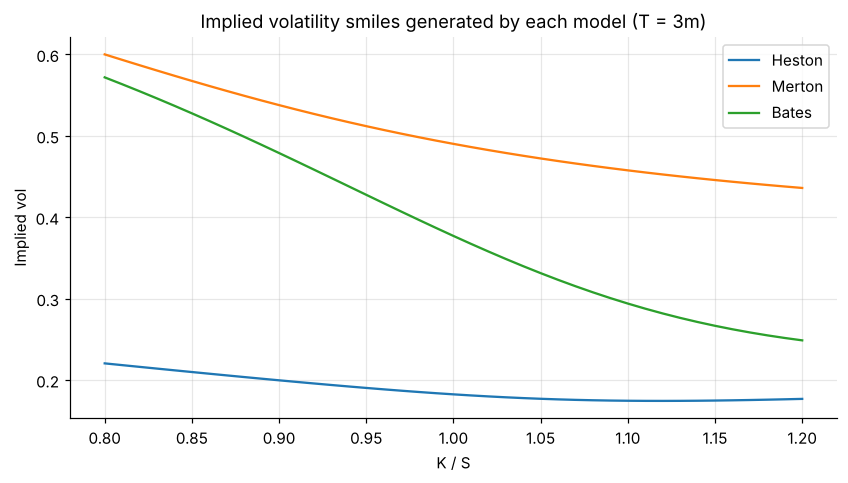

In [4]:
strikes = np.linspace(0.8 * S0, 1.2 * S0, 41)
def smile(prices):
    return [bs.implied_vol(p, S0, k, T, r) for k, p in zip(strikes, prices)]
plt.plot(strikes / S0, smile(heston.price(S0, strikes, T, r, hp)), label="Heston")
plt.plot(strikes / S0, smile(merton.price(S0, strikes, T, r, mp)), label="Merton")
plt.plot(strikes / S0, smile(bates.price(S0, strikes, T, r, bp)), label="Bates")
plt.title("Implied volatility smiles generated by each model (T = 3m)"); plt.xlabel("K / S"); plt.ylabel("Implied vol"); plt.legend()
plt.savefig(IMG / "model_smiles.png", bbox_inches="tight"); plt.show()

## Effect of correlation on the Heston skew

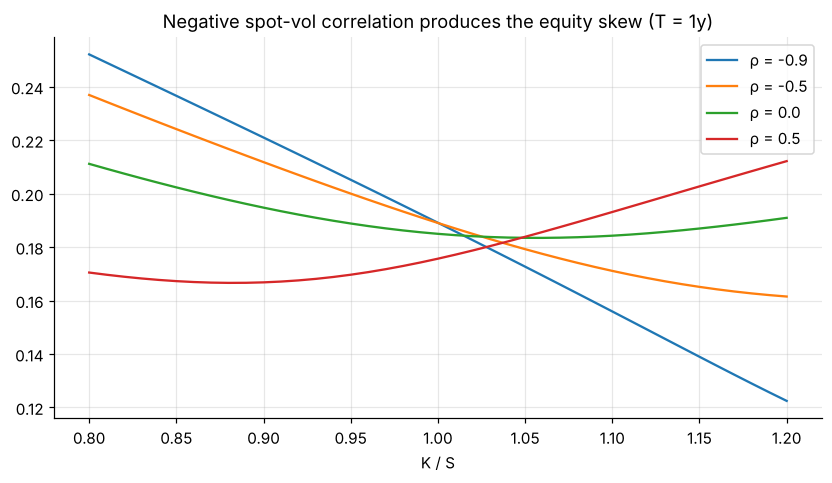

In [5]:
for rho in (-0.9, -0.5, 0.0, 0.5):
    p = heston.HestonParams(0.04, 2.0, 0.04, 0.6, rho)
    iv = [bs.implied_vol(px, S0, k, 1.0, r) for k, px in zip(strikes, heston.price(S0, strikes, 1.0, r, p))]
    plt.plot(strikes / S0, iv, label=f"ρ = {rho}")
plt.title("Negative spot-vol correlation produces the equity skew (T = 1y)"); plt.xlabel("K / S"); plt.legend(); plt.show()

## Simulated paths: stochastic variance and jumps

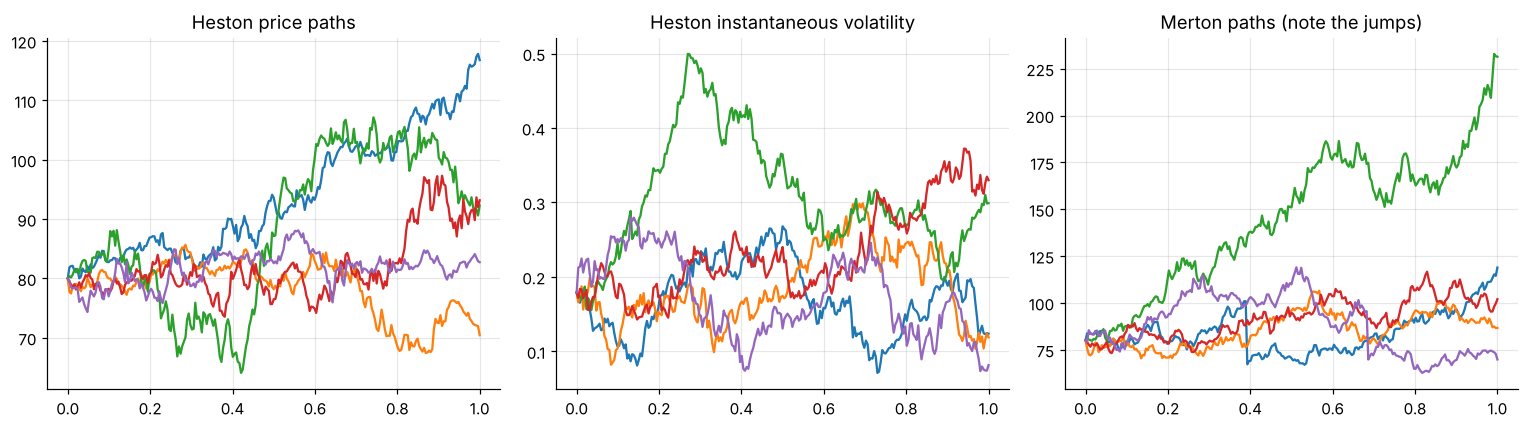

In [6]:
S_h, v_h = heston.simulate(S0, 1.0, r, hp, n_steps=252, n_paths=5, seed=3, return_var=True)
S_m = merton.simulate(S0, 1.0, r, mp, n_steps=252, n_paths=5, seed=3)
t = np.linspace(0, 1, 253)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(t, S_h); ax[0].set_title("Heston price paths")
ax[1].plot(t, np.sqrt(v_h)); ax[1].set_title("Heston instantaneous volatility")
ax[2].plot(t, S_m); ax[2].set_title("Merton paths (note the jumps)")
fig.tight_layout(); plt.show()

## Barrier options under Heston
The barrier pricer accepts any simulated paths, so path-dependent payoffs can be priced under stochastic volatility.

In [7]:
from derivpricer import monte_carlo as mc
S_paths = heston.simulate(S0, T, r, heston.HestonParams(0.032, 1.8, 0.045, 0.35, -0.70), n_steps=200, n_paths=100_000)
for K_, H_ in [(80, 90), (80, 95), (85, 95)]:
    uai = mc.barrier(S0, K_, H_, T, r, None, kind="up-and-in", paths=S_paths)
    eur = mc.barrier(S0, K_, 0, T, r, None, kind="up-and-in", paths=S_paths)
    print(f"Up-and-in call K={K_}, H={H_}: {uai.price:.4f} ± {1.96*uai.std_error:.4f}   vanilla {eur.price:.4f}   ratio {uai.price/eur.price:.1%}")

Up-and-in call K=80, H=90: 1.6205 ± 0.0250   vanilla 3.5028   ratio 46.3%
Up-and-in call K=80, H=95: 0.3471 ± 0.0144   vanilla 3.5028   ratio 9.9%
Up-and-in call K=85, H=95: 0.2362 ± 0.0100   vanilla 1.2231   ratio 19.3%
